
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/13_Lab_PinnsII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt

#Diferenciación automática

In [2]:
def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da


def tanhiperbolica2(a, da, d2a):
    A, dA = tanhiperbolica(a, da)
    A2, dA2 = producto(A, dA, A, dA)
    G, dG = suma(1, 0, -A2, -dA2)
    _, d2A = producto(G, dG, da, d2a)
    return A, dA, d2A

Computemos la deriva de:

$f(x) = x^2$


$f(x) = (2x+1)^2$

In [3]:
x = 2.2

In [4]:
derivadaX = producto(x, 1, x, 1)
derivadaX

(4.840000000000001, 4.4)

In [5]:
u, du = producto(2, 0, x, 1)
c, dc = suma(u, du, 1, 0)
producto(c, dc, c, dc)

(29.160000000000004, 21.6)

In [6]:
x = np.linspace(0, 2*np.pi)

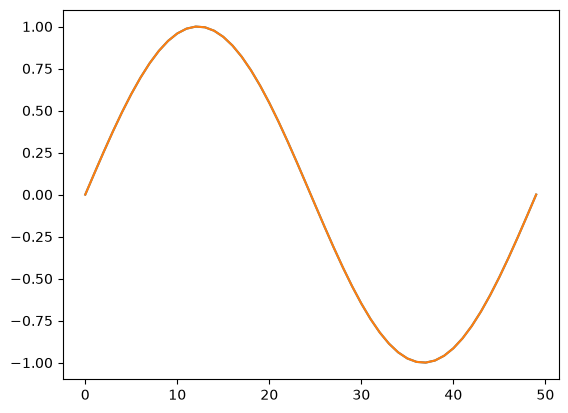

In [7]:
plt.plot(np.sin(x))
plt.plot(seno(x, 1)[0])

$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [8]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

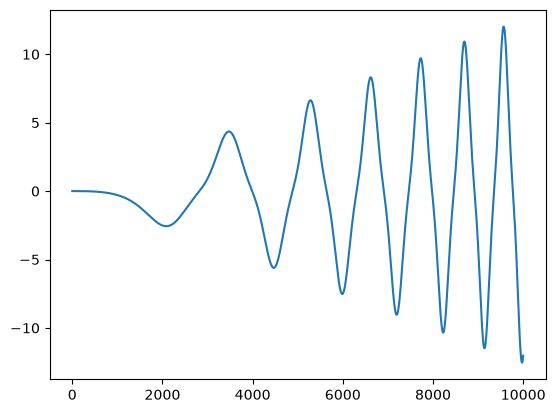

In [9]:
plt.plot(dr)

Supongamos que tenemos dos conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



In [10]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

In [11]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2




(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

In [12]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [13]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [14]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [15]:
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + params['delta'] * np.exp(-alpha*np.pi**2*(1/Lx**2 + 1/Ly**2)*t)*u


In [16]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

In [17]:
def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

In [18]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)

X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)

In [19]:
np.min(Temperatura[0])

np.float64(300.0)

In [20]:
np.max(Temperatura[0,:,:])

np.float64(399.706897857718)

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors


def graficar_planos(Temperatura, Lx, Ly, tiempos=None, n_planos=5, opacidad=0.5):
    """Planos T(x, y) en `n_planos` tiempos, incluidos el primero y el último, apilados sobre el eje temporal."""
    nt, nx, ny = Temperatura.shape
    X, Y = np.meshgrid(np.linspace(0, Lx, nx), np.linspace(0, Ly, ny), indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)
    indices = np.unique(np.linspace(0, nt - 1, min(n_planos, nt), dtype=int))

    norma = colors.Normalize(np.nanmin(Temperatura), np.nanmax(Temperatura))  # escala de colores común
    mapa = plt.get_cmap("jet")

    fig = plt.figure(figsize=(9, 6))
    eje = fig.add_subplot(projection="3d")
    for k in indices:
        color = mapa(norma(Temperatura[k]))
        color[..., 3] = opacidad
        eje.plot_surface(np.full(X.shape, tiempos[k], dtype=float), X, Y, facecolors=color,
                         rstride=1, cstride=1, linewidth=0, shade=False)
    eje.set(xlabel=titulo_t, ylabel="x [m]", zlabel="y [m]")
    eje.set_box_aspect((1.6, 1, Ly / Lx))
    eje.view_init(elev=20, azim=-135)
    fig.colorbar(cm.ScalarMappable(norma, mapa), ax=eje, shrink=0.6, label="Temperatura [°C]")
    return fig

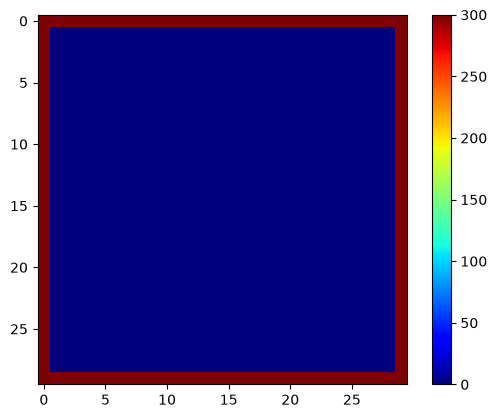

In [22]:
plt.imshow(Temperatura[1], cmap='jet')
plt.colorbar()
plt.show()

In [23]:
for i in range(1, len(t)):
  Temperatura[i,:,:] =  T(X, Y, t[i], **params)

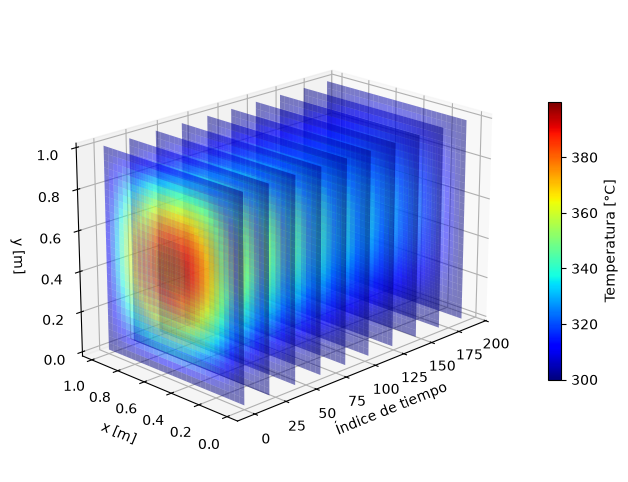

In [24]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
plt.show()

In [25]:
np.shape(Temperatura)

(188, 30, 30)

In [26]:
n_frames =len(Temperatura)# min(100), Temperatura.shape[0])
n_frames

188

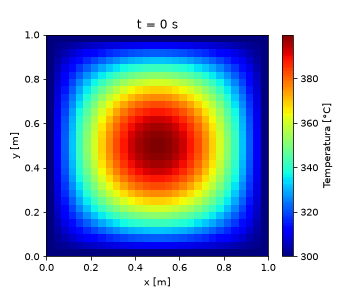

In [27]:
import tempfile
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

fig, eje = plt.subplots(figsize=(5, 4))
imagen = eje.imshow(Temperatura[0].T, origin="lower", extent=[0, Lx, 0, Ly], cmap="jet",
                    vmin=np.nanmin(Temperatura), vmax=np.nanmax(Temperatura))
fig.colorbar(imagen, ax=eje, label="Temperatura [°C]")
eje.set(xlabel="x [m]", ylabel="y [m]")


def actualizar(k):
    imagen.set_data(Temperatura[k].T)
    eje.set_title(f"t = {t[k]:.0f} s")
    return (imagen,)


# 48 cuadros (incluidos el primero y el último), guardados como GIF: se ve en cualquier visor de notebooks
animacion = FuncAnimation(fig, actualizar, frames=np.linspace(0, nt - 1, 48, dtype=int))
with tempfile.TemporaryDirectory() as carpeta:
    animacion.save(f"{carpeta}/animacion.gif", writer=PillowWriter(fps=8), dpi=72)
    gif = Image(filename=f"{carpeta}/animacion.gif")
plt.close(fig)
gif


# Physics-Informed Machine Learning (PIML)

Consideremos la ecuación de difusión de calor en dos dimensiones:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2 T}{\partial x^2}
+
\frac{\partial^2 T}{\partial y^2}
\right),
$$

donde $\alpha$ es la difusividad térmica.

## 1. Modelo neuronal con tangente hiperbólica

Consideremos una neurona definida por:

$$
Z_\theta(x,y,t)=\theta_1 x+\theta_2 y+\theta_3 t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=\tanh(Z_\theta).
$$

## 2. Modelo neuronal con activación gaussiana

Conservando una sola neurona, podemos incorporar una dependencia espacial cuadrática:

$$
Z_\theta(x,y,t)=
\theta_1(x-x_c)^2+
\theta_2(y-y_c)^2+
\theta_3t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=e^{-Z_\theta}.
$$

Esta función permite representar distribuciones localizadas de temperatura, con un máximo espacial cuando los coeficientes cuadráticos son positivos.

## 3. Función de coste física

Para cualquiera de los dos modelos, definimos el residuo:

$$
R_\theta(x_i,y_i,t_i)=
\frac{\partial T_\theta}{\partial t}
-
\alpha\left(
\frac{\partial^2T_\theta}{\partial x^2}
+
\frac{\partial^2T_\theta}{\partial y^2}
\right).
$$

La función de coste es:

$$
J_{\mathrm{fisica}}(\theta)=
\frac{1}{M}\sum_{i=1}^{M}
R_\theta(x_i,y_i,t_i)^2.
$$

Las derivadas se calculan mediante diferenciación automática.

## 4. Condiciones iniciales y de frontera

Si conocemos las temperaturas iniciales y de frontera, incorporamos sus errores:

$$
J(\theta)=
J_{\mathrm{fisica}}
+
J_{\mathrm{inicial}}
+
J_{\mathrm{frontera}}.
$$

Finalmente, los parámetros se actualizan mediante descenso de gradiente:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-\eta\nabla_\theta J.
$$

Ambos modelos tienen cuatro parámetros entrenables: tres pesos y un sesgo. La diferencia principal está en la función utilizada para representar el campo de temperaturas.


Para entrenar la red construiremos un vector de entrada como sigue:
https://www.sciencedirect.com/science/article/pii/S0021999118307125

\begin{equation}
\mathbf Q=
\begin{pmatrix}
x_1&y_1&t_0\\
x_2&y_2&t_0\\
\vdots&\vdots&\vdots\\
x_N&y_N&t_0
\end{pmatrix}
\end{equation}




In [28]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [29]:
def T(x, y, t, **params):
  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + params['delta'] * np.exp(-alpha*np.pi**2*(1/Lx**2 + 1/Ly**2)*t)*u


In [30]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

In [31]:
def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

In [32]:
tf = np.max(t) - np.min(t)
tf

np.float64(500.0)

In [33]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)
X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)


In [34]:
X1 = x.reshape((len(x), 1))
Y1 = y.reshape((len(y), 1))
tk = t.reshape((len(t), 1))/np.max(t)

In [35]:
Q=np.zeros((30*30*nt, 3))
p=0
for k in range(0, nt):
  for i in range(0, nx):
    for j in range(0, ny):
      Q[p] = np.array([ t[k],x[i], y[j]])
      p=p+1

# Selección de los bordes

In [36]:
tt = Q[:,0].reshape(nt, nx, ny)
xx = Q[:,1].reshape(nt, nx, ny)
yy = Q[:,2].reshape(nt, nx, ny)
borde = (
    np.isclose(xx, x[0]) |
    np.isclose(xx, x[-1]) |
    np.isclose(yy, y[0]) |
    np.isclose(yy, y[-1])
)
borde_concatenado = borde.reshape(-1)

In [37]:
Q_borde = Q[borde_concatenado]
Q_borde

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.44827586e-02],
       [0.00000000e+00, 0.00000000e+00, 6.89655172e-02],
       ...,
       [5.00000000e+02, 1.00000000e+00, 9.31034483e-01],
       [5.00000000e+02, 1.00000000e+00, 9.65517241e-01],
       [5.00000000e+02, 1.00000000e+00, 1.00000000e+00]], shape=(21808, 3))

In [38]:
T_borde = Temperatura[borde].reshape(-1, 1)
print(Q_borde.shape)
print(T_borde.shape)

(21808, 3)
(21808, 1)


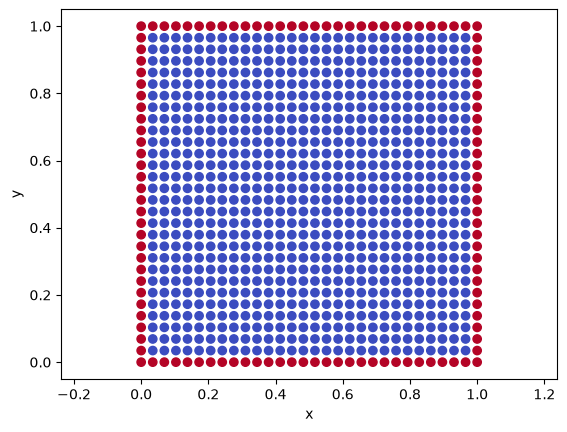

In [39]:
plt.scatter(xx[0], yy[0], c=borde[0], cmap="coolwarm")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

## Condicion inicial

In [40]:
inicial = np.isclose(tt, t[0])
Q_ini = Q[inicial.reshape(-1)]
T_ini = Temperatura[inicial].reshape(-1, 1)
print(Q_ini.shape)
print(T_ini.shape)

(900, 3)
(900, 1)


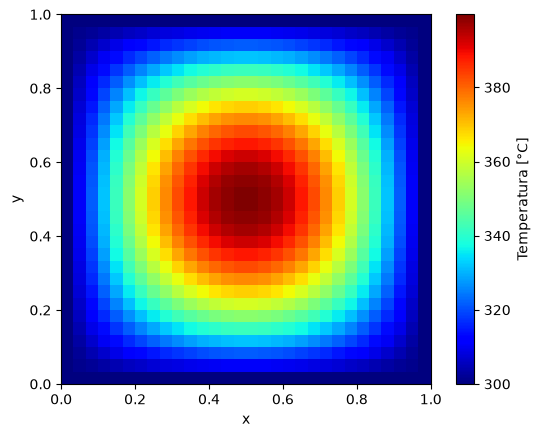

In [41]:
plt.imshow(
    Temperatura[0].T,
    origin="lower",
    extent=[x[0], x[-1], y[0], y[-1]],
    cmap="jet"
)

plt.colorbar(label="Temperatura [°C]")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [42]:
#Normalizacion
delta_T = max(np.max(np.abs(T_ini - Tb)), 1.0)
u_ini = (T_ini - Tb) / delta_T
u_borde = (T_borde - Tb) / delta_T

In [43]:
interior = ~borde & ~inicial

Q_f = Q[interior.reshape(-1)]

El cuerpo del bucle de la plantilla se agrupó en la función `costo_tanh`, que devuelve las tres pérdidas y el gradiente. De esta forma se puede verificar el gradiente y guardar cada componente de la pérdida por separado.

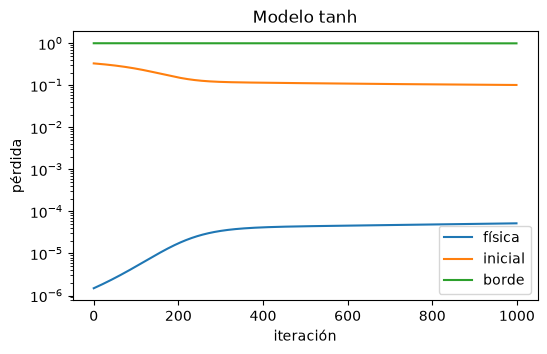

In [44]:
# Derivadas de Z respecto a (wt, wx, wy, b)
dZ = np.column_stack((Q_f, np.ones(len(Q_f))))
dZ_ini = np.column_stack((Q_ini, np.ones(len(Q_ini))))
dZ_borde = np.column_stack((Q_borde, np.ones(len(Q_borde))))


def costo_tanh(W, B):
    """[J_fisica, J_ini, J_borde] y gradiente de J respecto a (wt, wx, wy, b) para T = tanh(Z)."""
    Z = Q_f @ W + B

    # Derivadas
    _, dA_dt, _ = tanhiperbolica2(Z, W[0, 0], 0)
    _, _, d2A_dx2 = tanhiperbolica2(Z, W[1, 0], 0)
    _, _, d2A_dy2 = tanhiperbolica2(Z, W[2, 0], 0)
    R = dA_dt - alpha * (d2A_dx2 + d2A_dy2)
    J_fisica = np.mean(R**2)

    # Derivadas de tanh respecto a Z
    A, G, H = tanhiperbolica2(Z, 1, 0)
    _, K = producto(-2*A, -2*G, G, H)

    # Gradientes del residuo
    wt, wx, wy = W[:, 0]
    C = wt*H - alpha*(wx**2 + wy**2)*K
    dR = C*dZ
    dR[:, 0] += G[:, 0]
    dR[:, 1] -= 2*alpha*wx*H[:, 0]
    dR[:, 2] -= 2*alpha*wy*H[:, 0]
    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.tanh(Q_ini @ W + B)
    J_ini = np.mean((A_ini - u_ini)**2)
    ei = (A_ini - u_ini) * (1 - A_ini**2)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condiciones de frontera
    A_borde = np.tanh(Q_borde @ W + B)
    J_borde = np.mean((A_borde - u_borde)**2)
    eb = (A_borde - u_borde) * (1 - A_borde**2)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    return np.array([J_fisica, J_ini, J_borde]), gradiente


def entrenar(costo, W, B, eta, n_iter):
    """Descenso de gradiente sobre W y B (en el sitio). Devuelve la historia de las tres pérdidas."""
    historia = []
    for _ in range(n_iter):
        J, gradiente = costo(W, B)
        W[:, 0] -= eta * gradiente[:3]
        B[0, 0] -= eta * gradiente[3]
        historia.append(J)
    return np.array(historia)


def graficar_perdidas(historia, titulo):
    plt.figure(figsize=(6, 3.5))
    for k, nombre in enumerate(["física", "inicial", "borde"]):
        plt.semilogy(historia[:, k], label=nombre)
    plt.xlabel("iteración")
    plt.ylabel("pérdida")
    plt.title(titulo)
    plt.legend()
    plt.show()


np.random.seed(42)
W = np.random.random((3, 1))
B = np.random.random((1, 1))
historia_tanh = entrenar(costo_tanh, W, B, eta=0.01, n_iter=1000)
W_tanh, B_tanh = W.copy(), B.copy()
graficar_perdidas(historia_tanh, "Modelo tanh")

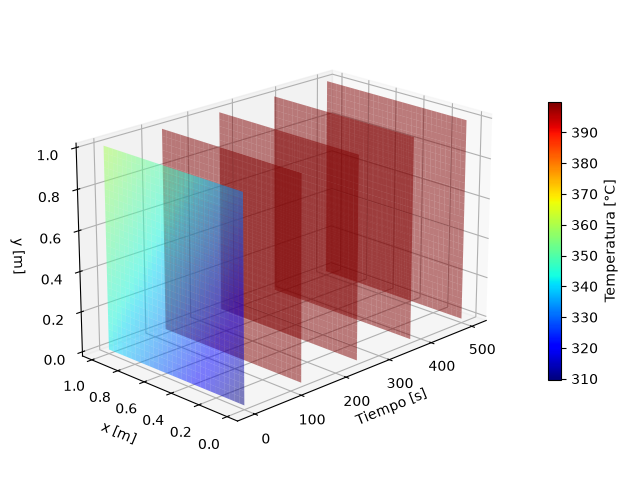

In [45]:
Temperatura_tanh = Tb + delta_T*np.tanh(Q @ W_tanh + B_tanh).reshape(nt, nx, ny)

graficar_planos(Temperatura_tanh, Lx, Ly, tiempos=t, n_planos=5)
plt.show()

## Modelo gaussiano

Implementar el mismo código para una función de la forma $T_\theta=e^{-Z_\theta}$, con $Z_\theta=w_t\tau+w_x\xi^2+w_y\eta^2+b$, donde $\tau=t/t_f$, $\xi=x/L_x-\tfrac12$ y $\eta=y/L_y-\tfrac12$.

In [46]:
def caracteristicas(Q):
    tau = (Q[:, 0:1] - t[0]) / tf
    xi = (Q[:, 1:2] - x[0]) / Lx - 0.5
    yi = (Q[:, 2:3] - y[0]) / Ly - 0.5

    P = np.hstack((tau, xi**2, yi**2))

    return P, xi, yi

P, xi, yi = caracteristicas(Q)
P_ini, _, _ = caracteristicas(Q_ini)
P_borde, _, _ = caracteristicas(Q_borde)

In [47]:
W = np.random.random((3, 1))
B = np.random.random((1, 1))

Z = P @ W + B
A = np.exp(-Z)

In [48]:
def exponencial(a, da):
    A = np.exp(a)
    return A, A*da

def exponencial2(a, da, d2a):
    A, dA = exponencial(a, da)
    _, d2A = producto(A, dA, da, d2a)
    return A, dA, d2A

In [49]:
wt, wx, wy = W[:, 0]

_, dA_dt, _ = exponencial2(-Z, -wt, 0)

_, _, d2A_dx2 = exponencial2(
    -Z, -2*wx*xi, -2*wx
)

_, _, d2A_dy2 = exponencial2(
    -Z, -2*wy*yi, -2*wy
)

In [50]:
ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2

J_fisica = np.mean(R**2)

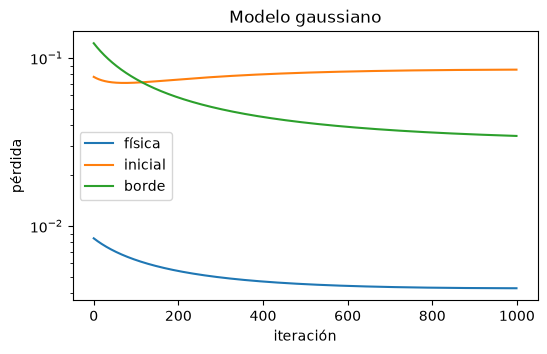

In [51]:
ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

# Derivadas de Z respecto a (wt, wx, wy, b)
dP = np.column_stack((P, np.ones(len(P))))
dP_ini = np.column_stack((P_ini, np.ones(len(P_ini))))
dP_borde = np.column_stack((P_borde, np.ones(len(P_borde))))

et, ex, ey = np.eye(4)[:3]


def costo_gauss(W, B):
    """[J_fisica, J_ini, J_borde] y gradiente de J respecto a (wt, wx, wy, b) para T = exp(-Z)."""
    Z = P @ W + B
    A = np.exp(-Z)
    wt, wx, wy = W[:, 0]

    # Derivadas automáticas respecto a las coordenadas
    _, dA_dt, _ = exponencial2(-Z, -wt, 0)
    _, _, d2A_dx2 = exponencial2(-Z, -2*wx*xi, -2*wx)
    _, _, d2A_dy2 = exponencial2(-Z, -2*wy*yi, -2*wy)
    R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2
    J_fisica = np.mean(R**2)

    # Gradientes del residuo respecto a W y B
    px, dpx = producto(2*xi, 0, wx, ex)
    py, dpy = producto(2*yi, 0, wy, ey)
    Fx, dFx = producto(px, dpx, px, dpx)
    Fx, dFx = suma(Fx, dFx, -2*wx, -2*ex)
    Fy, dFy = producto(py, dpy, py, dpy)
    Fy, dFy = suma(Fy, dFy, -2*wy, -2*ey)
    C, dC = suma(-wt, -et, -ax*Fx, -ax*dFx)
    C, dC = suma(C, dC, -ay*Fy, -ay*dFy)
    _, dR = producto(A, -A*dP, C, dC)
    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.exp(-(P_ini @ W + B))
    J_ini = np.mean((A_ini - u_ini)**2)
    ei = (A_ini - u_ini) * (-A_ini)
    gradiente += 2*np.mean(ei*dP_ini, axis=0)

    # Condición de frontera
    A_borde = np.exp(-(P_borde @ W + B))
    J_borde = np.mean((A_borde - u_borde)**2)
    eb = (A_borde - u_borde) * (-A_borde)
    gradiente += 2*np.mean(eb*dP_borde, axis=0)

    return np.array([J_fisica, J_ini, J_borde]), gradiente


np.random.seed(42)
W = np.random.random((3, 1))
B = np.random.random((1, 1))
historia_gauss = entrenar(costo_gauss, W, B, eta=0.01, n_iter=1000)
W_gauss, B_gauss = W.copy(), B.copy()
graficar_perdidas(historia_gauss, "Modelo gaussiano")

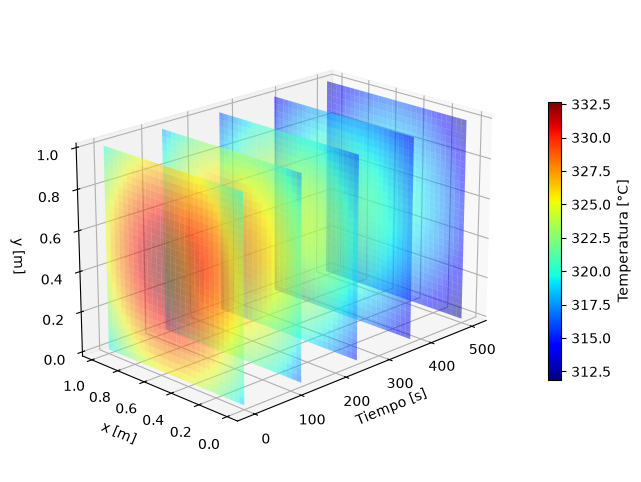

In [52]:
Temperatura_gauss = Tb + delta_T*np.exp(-(P @ W_gauss + B_gauss)).reshape(nt, nx, ny)

graficar_planos(Temperatura_gauss, Lx, Ly, tiempos=t, n_planos=5)
plt.show()

## Validación

### Gradientes

El gradiente derivado a mano se compara con uno numérico, calculado con diferencias centradas de $J=J_\text{fisica}+J_\text{ini}+J_\text{borde}$ en los parámetros entrenados.

In [53]:
def gradiente_numerico(costo, W, B, h=1e-6):
    theta = np.r_[W[:, 0], B[0]]
    J = lambda v: costo(v[:3, None], v[3:, None])[0].sum()
    return np.array([(J(theta + h * e) - J(theta - h * e)) / (2 * h) for e in np.eye(4)])


for nombre, costo, W_, B_ in [("tanh", costo_tanh, W_tanh, B_tanh), ("gaussiano", costo_gauss, W_gauss, B_gauss)]:
    analitico, numerico = costo(W_, B_)[1], gradiente_numerico(costo, W_, B_)
    print(f"{nombre:10s} analítico: {analitico.round(6)}  numérico: {numerico.round(6)}  "
          f"diferencia relativa: {np.abs(analitico - numerico).max() / np.abs(numerico).max():.1e}")

tanh       analítico: [ 0.014262  0.028394  0.01691  -0.020236]  numérico: [ 0.014262  0.028394  0.01691  -0.020236]  diferencia relativa: 5.5e-09


gaussiano  analítico: [-0.00384  -0.014688 -0.01561  -0.002674]  numérico: [-0.00384  -0.014688 -0.01561  -0.002674]  diferencia relativa: 3.5e-10


### Comparación con la solución analítica

Además se busca el mínimo de $J$ con L-BFGS-B, usando el gradiente ya verificado y partiendo de los parámetros entrenados. Las tolerancias son más estrictas que las de `scipy`, porque con las de defecto el modelo tanh se detiene antes del mínimo. Así se puede separar lo que el modelo no es capaz de representar de lo que el descenso de gradiente simplemente no alcanzó.

In [54]:
import pandas as pd
from scipy.optimize import minimize


def J_y_gradiente(v, costo):
    J, gradiente = costo(v[:3, None], v[3:, None])
    return J.sum(), gradiente


campos = {
    "tanh": (costo_tanh, lambda v: Tb + delta_T * np.tanh(Q @ v[:3, None] + v[3]).reshape(nt, nx, ny),
             np.r_[W_tanh[:, 0], B_tanh[0]]),
    "gaussiano": (costo_gauss, lambda v: Tb + delta_T * np.exp(-(P @ v[:3, None] + v[3])).reshape(nt, nx, ny),
                  np.r_[W_gauss[:, 0], B_gauss[0]]),
}
Temperatura_analitica = T(X, Y, t[:, None, None], **params)

filas, errores = {}, {}
for nombre, (costo, campo, v_dg) in campos.items():
    v_opt = minimize(J_y_gradiente, v_dg, args=(costo,), jac=True, method="L-BFGS-B",
                     options={"ftol": 1e-15, "gtol": 1e-10}).x
    for metodo, v in [("descenso de gradiente", v_dg), ("L-BFGS-B", v_opt)]:
        error = campo(v) - Temperatura_analitica
        errores[nombre, metodo] = error
        filas[nombre, metodo] = [*costo(v[:3, None], v[3:, None])[0], *v, np.abs(error).max(),
                                 np.linalg.norm(error) / np.linalg.norm(Temperatura_analitica - Tb)]

print(f"w_t teórico del modelo gaussiano: (ax + ay)·π² = {(ax + ay) * np.pi**2:.3f}")
pd.DataFrame(filas, index=["J_fisica", "J_ini", "J_borde", "w_t", "w_x", "w_y", "b",
                           "error máx. [°C]", "error L2 rel."]).T.round(4)

w_t teórico del modelo gaussiano: (ax + ay)·π² = 0.987


J_fisica   J_ini  J_borde     w_t     w_x  \
tanh      descenso de gradiente    0.0001  0.1016   0.9932  0.2866  0.3559   
          L-BFGS-B                 0.0000  0.0976   0.0232 -0.0009 -0.0000   
gaussiano descenso de gradiente    0.0043  0.0852   0.0343  0.4740  1.1752   
          L-BFGS-B                 0.0204  0.0124   0.0094  0.7682  5.8142   

                                    w_y       b  error máx. [°C]  \
tanh      descenso de gradiente  0.2502  0.0978          99.7069   
          L-BFGS-B              -0.0000  0.3088          69.8623   
gaussiano descenso de gradiente  0.9697  1.1164          67.0796   
          L-BFGS-B               5.8142  0.2067          18.9201   

                                 error L2 rel.  
tanh      descenso de gradiente         2.4518  
          L-BFGS-B                      0.8311  
gaussiano descenso de gradiente         0.5662  
          L-BFGS-B                      0.1996

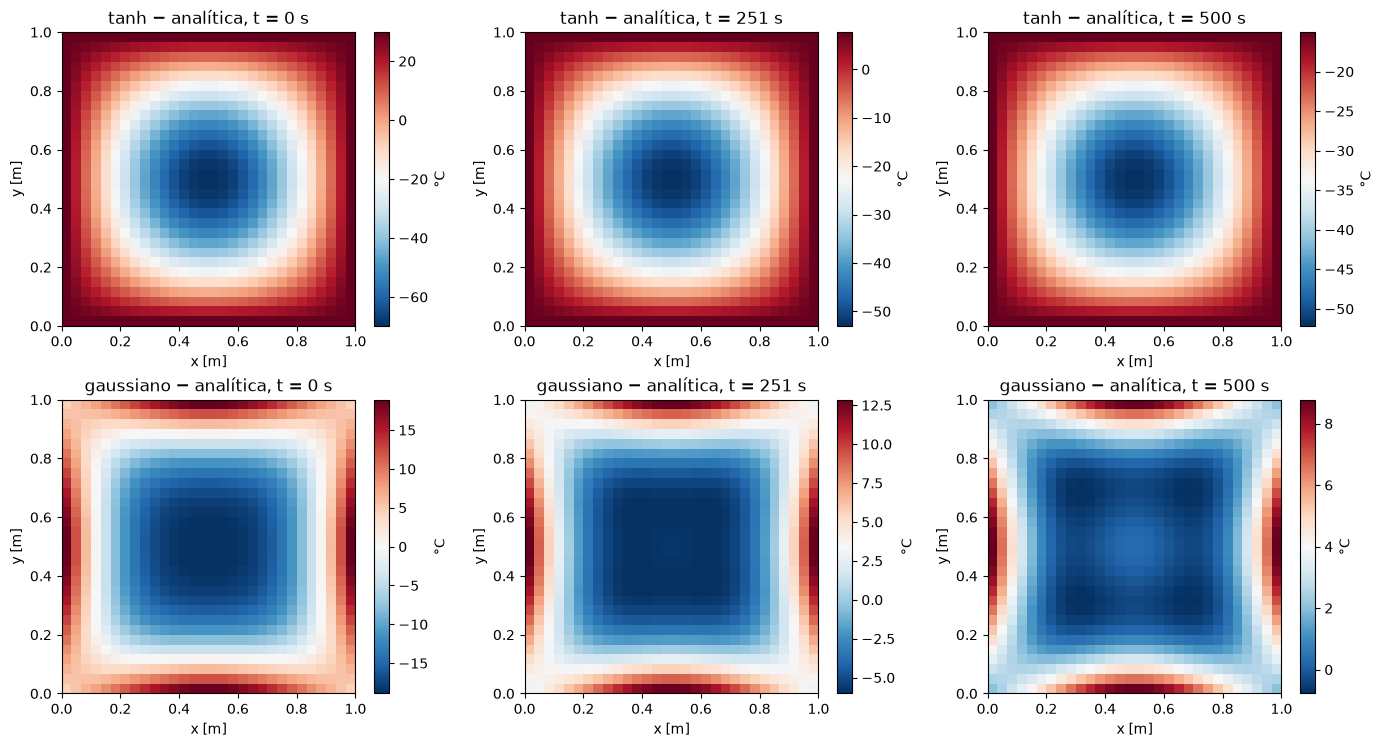

In [55]:
indices = [0, nt // 2, nt - 1]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for fila, nombre in enumerate(["tanh", "gaussiano"]):
    for j, k in enumerate(indices):
        im = axes[fila, j].imshow(errores[nombre, "L-BFGS-B"][k].T, origin="lower", extent=[0, Lx, 0, Ly], cmap="RdBu_r")
        fig.colorbar(im, ax=axes[fila, j], label="°C")
        axes[fila, j].set(title=f"{nombre} − analítica, t = {t[k]:.0f} s", xlabel="x [m]", ylabel="y [m]")
plt.tight_layout()
plt.show()

En los dos modelos los gradientes derivados a mano coinciden con los numéricos, con una diferencia relativa del orden de $10^{-8}$ o menor, así que los errores no vienen de ahí.

En el modelo tanh, como $t$ no está normalizado ($t\in[0,500]$), el término $w_t t$ satura la tanh. La red predice $T\approx T_b+\Delta T$ para casi todo $t>0$, y en 1000 iteraciones $J_\text{borde}\approx1$ no baja. El residuo físico sale pequeño solo porque el campo saturado es casi constante. Aunque se entrene hasta el mínimo, una tanh de una función lineal es monótona en la dirección $(w_x,w_y)$ y no puede formar el domo. El óptimo termina siendo un campo uniforme en el espacio ($w_x=w_y=0$) que solo varía en el tiempo, con hasta 70 °C de error en el centro.

El modelo gaussiano sí tiene la forma del domo, y en el óptimo el error baja a 19 °C ($L^2$ relativo de 0.20). Los 1000 pasos de descenso de gradiente de la plantilla quedan lejos de ese mínimo ($J=0.124$ frente a 0.042). Lo que queda de error es estructural, porque la gaussiana no se anula en los bordes. El ajuste lo compensa estrechando la campana, con $w_x=w_y=5.8$ en lugar de $\pi^2/2\approx4.9$ (el valor que reproduce la curvatura de $\sin\pi\xi$ en el centro), y reduciendo la amplitud inicial a $e^{-b}=0.81$. Por eso el error es máximo en $t=0$, con −19 °C en el centro y +19 °C en el punto medio de cada borde. El decaimiento aprendido, $w_t=0.77$, es del orden del teórico (0.987) pero no igual, ya que $w_t$ también compensa esos errores espaciales.

Como ninguno de los dos modelos de una neurona contiene la solución $e^{-2\pi^2\kappa\tau}\sin\pi\xi\,\sin\pi\eta$, con un buen optimizador el error queda determinado por la forma del modelo y no por el entrenamiento.